# Класифікація дій за даними смартфона

Лабораторна робота № 1 · Гліб Плахтій

## 1. Дані

Мета - передбачити `Activity` для нового учасника за вимірюваннями акселерометра та гіроскопа. У наборі 30 учасників. Один рядок містить 561 числову ознаку, обчислену за 2,56 с запису зі смартфона на поясі. [Датасет на Kaggle](https://www.kaggle.com/datasets/uciml/human-activity-recognition-with-smartphones) · [Опис ознак в UCI](https://archive.ics.uci.edu/dataset/240/human+activity+recognition+using+smartphones)



In [ ]:
from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, display
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

SEED = 42
LABELS = ["WALKING", "WALKING_UPSTAIRS", "WALKING_DOWNSTAIRS", "SITTING", "STANDING", "LAYING"]

In [ ]:
DATASET = "uciml/human-activity-recognition-with-smartphones/versions/1"

def read_split(filename):
    path = Path("data/har") / filename
    if not path.is_file():
        path = Path(kagglehub.dataset_download(DATASET, path=filename))
        if path.is_dir():
            path = path / filename
    return pd.read_csv(path)

train, test = read_split("train.csv"), read_split("test.csv")
print(f"Train: {train.shape} · Test: {test.shape} · Total: {len(train) + len(test)} × {len(train.columns)}")

### Стовпці, типи та пропуски

Цільова змінна - `Activity`, ідентифікатор учасника - `subject`. Решта 561 стовпець містить ознаки. Наприклад, `tBodyAccMag-std()` - стандартне відхилення модуля прискорення тіла у вікні.

In [ ]:
data = pd.concat([train, test], ignore_index=True)
audit = pd.DataFrame({"dtype": data.dtypes, "missing": data.isna().sum()})
print("Total missing values:", audit["missing"].sum())
display(HTML("<details><summary>Column names, dtypes and missing values</summary>"
             + audit.to_html() + "</details>"))

## 2. Підготовка даних

У таблиці немає пропусків, усі ознаки числові. Імпутація й кодування не потрібні. Для навчання виключаємо `Activity` і `subject`.

Сусідні вікна одного запису перекриваються на 50%. Зберігаємо авторський поділ за учасниками, щоб фрагменти однієї людини не потрапили одночасно в train і test.

In [28]:
features = train.columns.drop(["subject", "Activity"])
X_train, X_test = train[features], test[features]
y_train, y_test = train["Activity"], test["Activity"]
groups = train["subject"]
assert set(groups).isdisjoint(test["subject"])
print(f"Participants: {groups.nunique()} train, {test['subject'].nunique()} test")

counts = pd.DataFrame({
    "Train": y_train.value_counts(), "Test": y_test.value_counts()
}).loc[LABELS]
counts["Total"] = counts.sum(axis=1)
counts["Share (%)"] = (100 * counts["Total"] / counts["Total"].sum()).round(2)
display(counts.rename_axis("Activity"))

Participants: 21 train, 9 test


,Train,Test,Total,Share (%)
Activity,,,,
WALKING,1226,496,1722,16.72
WALKING_UPSTAIRS,1073,471,1544,14.99
WALKING_DOWNSTAIRS,986,420,1406,13.65
SITTING,1286,491,1777,17.25
STANDING,1374,532,1906,18.51
LAYING,1407,537,1944,18.88


## 3. Аналіз навчальної вибірки

Для графіків обрано шість ознак. Розкид і енергія прискорення описують інтенсивність руху, розкид кутової швидкості - обертання, проєкції гравітації по X і Y - орієнтацію телефона, а середня частота - ритм руху. Ознаки подано у нормованій шкалі. Для навчання використовуємо всі 561.

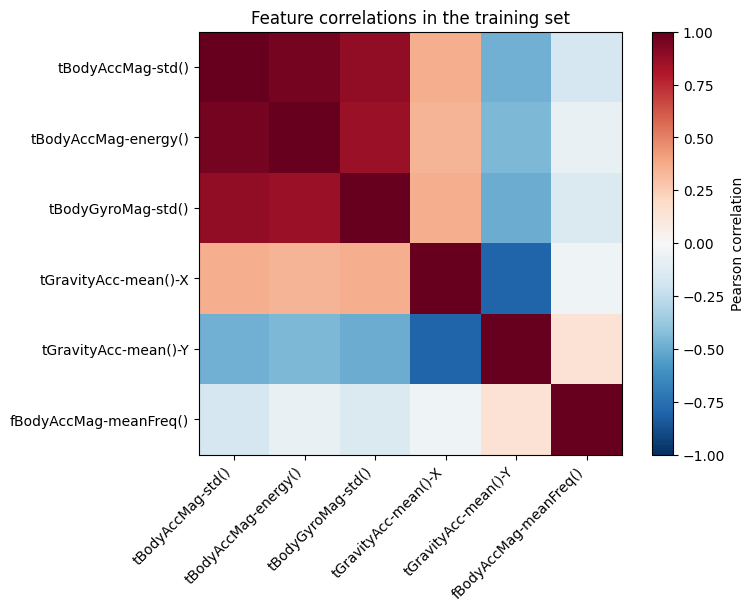

In [29]:
shown = [
    "tBodyAccMag-std()", "tBodyAccMag-energy()", "tBodyGyroMag-std()",
    "tGravityAcc-mean()-X", "tGravityAcc-mean()-Y", "fBodyAccMag-meanFreq()",
]
eda = X_train[shown]
corr = eda.corr()
fig, ax = plt.subplots(figsize=(8, 6), layout="constrained")
heat = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(shown)), shown, rotation=45, ha="right")
ax.set_yticks(range(len(shown)), shown)
ax.set_title("Feature correlations in the training set")
fig.colorbar(heat, ax=ax, label="Pearson correlation")
plt.show()

У `tBodyAccMag-std()` та `tBodyAccMag-energy()` сильна додатна кореляція (*r* = 0,96). Проєкції гравітації по X та Y мають від’ємну кореляцію (*r* = −0,80).

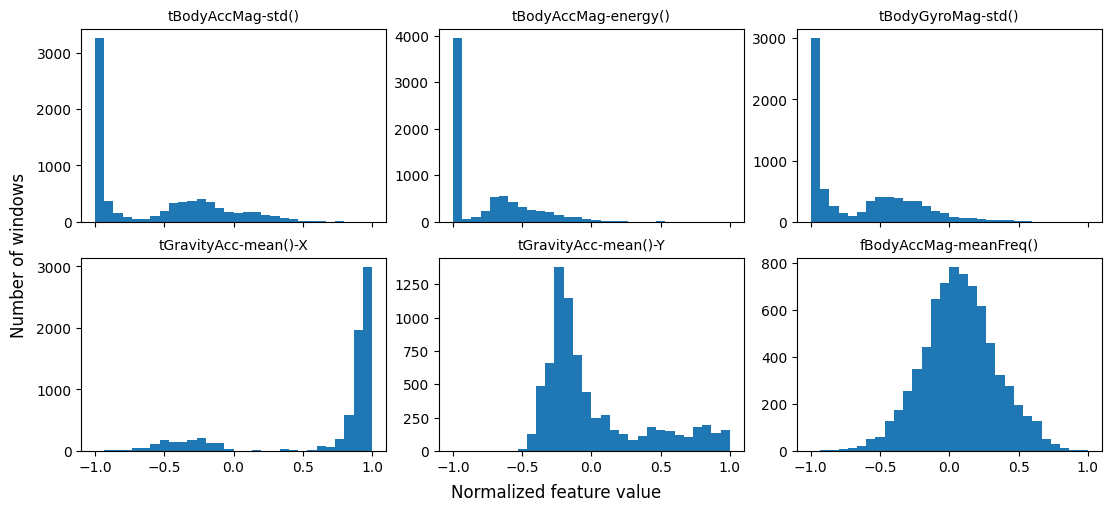

In [30]:
fig, axes = plt.subplots(2, 3, figsize=(11, 5), sharex=True, layout="constrained")
for ax, feature in zip(axes.flat, shown):
    ax.hist(eda[feature], bins=np.linspace(-1, 1, 31))
    ax.set_title(feature, fontsize=10)
fig.supxlabel("Normalized feature value")
fig.supylabel("Number of windows")
plt.show()

Розподіл `tBodyAccMag-std()` має пік біля −1. У 47,7% навчальних вікон значення цієї ознаки не перевищує −0,9.

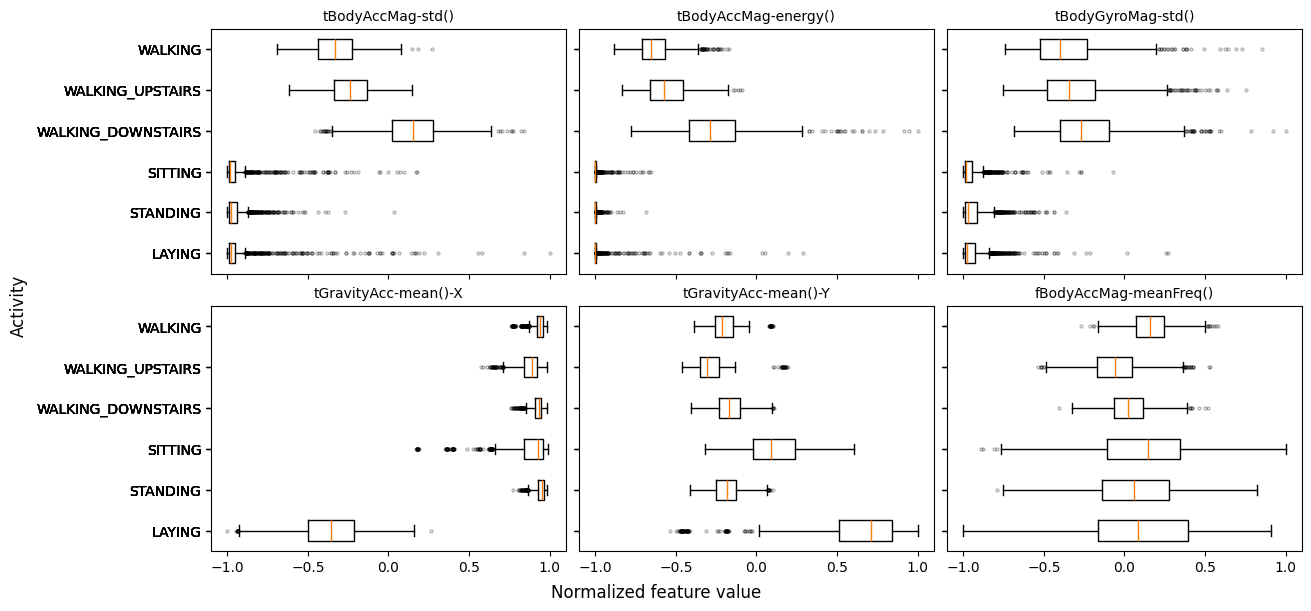

In [31]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharex=True, sharey=True, layout="constrained")
for ax, feature in zip(axes.flat, shown):
    values = [eda.loc[y_train == label, feature] for label in LABELS]
    ax.boxplot(values, orientation="horizontal", tick_labels=LABELS,
               flierprops={"markersize": 2, "alpha": 0.3})
    ax.set_title(feature, fontsize=10)
axes[0, 0].invert_yaxis()
fig.supxlabel("Normalized feature value")
fig.supylabel("Activity")
plt.show()

Для `SITTING`, `STANDING` та `LAYING` медіана `tBodyAccMag-std()` близька до −0,98. Для `WALKING` вона дорівнює −0,33, для `WALKING_UPSTAIRS` −0,24, а для `WALKING_DOWNSTAIRS` +0,15. Медіана гравітаційної проєкції по X відрізняє `LAYING` (−0,36) від `SITTING` (+0,93) і `STANDING` (+0,95).

## 4. Моделі та підбір параметрів

| Модель | Принцип класифікації |
|---|---|
| kNN | Голосування k найближчих навчальних прикладів. |
| Дерево рішень | Послідовні пороги ознак ведуть до листка з прогнозом класу. |
| SVM (RBF) | Подібність до опорних векторів визначає рішення попарних класифікаторів. |
| Випадковий ліс | Дерева навчаються на різних вибірках прикладів та ознак. Ліс усереднює їхні оцінки ймовірностей. |
| AdaBoost | Послідовно навчає дерева, підвищуючи вагу помилково класифікованих прикладів. |

Основна метрика - **macro F1**. Вона враховує precision і recall кожного класу та надає шести класам однакову вагу. Моделі порівнюємо на тих самих трьох групових фолдах train. Кожен учасник цілком належить одній валідаційній групі.

Для kNN і SVM відстані залежать від розкиду ознак. Їхні `Pipeline` навчають `StandardScaler` на навчальній частині кожного фолду. Моделі на деревах використовують пороги й працюють із початковими ознаками.

In [32]:
splitter = GroupKFold(n_splits=3, shuffle=True, random_state=SEED)
folds = list(splitter.split(X_train, y_train, groups))
neighbors = [3, 7, 15, 31]
c_values = [1, 10, 100]
gamma_values = [0.0003, 0.0018, 0.006]
assert max(neighbors) <= min(len(fit_idx) for fit_idx, _ in folds)

In [33]:
models = {
    "kNN": (make_pipeline(StandardScaler(), KNeighborsClassifier()),
            {"kneighborsclassifier__n_neighbors": neighbors}),
    "Decision tree": (DecisionTreeClassifier(random_state=SEED), {}),
    "SVM (RBF)": (make_pipeline(StandardScaler(), SVC(kernel="rbf")),
                  {"svc__C": c_values, "svc__gamma": gamma_values}),
    "Random forest": (RandomForestClassifier(n_estimators=120, random_state=SEED), {}),
    "AdaBoost": (
        AdaBoostClassifier(
            estimator=DecisionTreeClassifier(max_depth=3, max_features="sqrt"),
            n_estimators=50, random_state=SEED
        ), {}
    ),
}

searches = {}
for name, (model, grid) in models.items():
    search = GridSearchCV(model, grid, cv=folds, scoring="f1_macro", refit=True,
                          n_jobs=2, error_score="raise")
    searches[name] = search.fit(X_train, y_train)

In [34]:
cv_table = pd.DataFrame([
    {
        "Model": name,
        "Best parameters": {key.split("__")[-1]: value for key, value in search.best_params_.items()},
        "CV macro F1": search.best_score_,
    }
    for name, search in searches.items()
]).set_index("Model").sort_values("CV macro F1", ascending=False)
display(cv_table.round(4))

,Best parameters,CV macro F1
Model,,
SVM (RBF),"{'C': 100, 'gamma': 0.0003}",0.9308
Random forest,{},0.9117
AdaBoost,{},0.8810
kNN,{'n_neighbors': 31},0.8711
Decision tree,{},0.8322


Найвищий CV macro F1 отримала SVM (0,9308) за `C=100` і `gamma=0.0003`. Для kNN найкращим серед перевірених значень було `k=31` (0,8711).

## 5. Оцінка на тесті

Після підбору параметрів кожну модель навчено на всьому train. Тест містить 2 947 вікон дев’ятьох інших учасників. Рядки матриць відповідають справжнім класам, стовпці - прогнозам.

In [35]:
predictions = {name: search.predict(X_test) for name, search in searches.items()}
for name, prediction in predictions.items():
    print(name)
    print(classification_report(y_test, prediction, labels=LABELS, digits=3, zero_division=0))
    matrix = confusion_matrix(y_test, prediction, labels=LABELS)
    display(pd.DataFrame(matrix, index=pd.Index(LABELS, name="Activity"),
                         columns=pd.Index(LABELS, name="Prediction")))

kNN
                    precision    recall  f1-score   support

           WALKING      0.809     0.988     0.889       496
  WALKING_UPSTAIRS      0.875     0.894     0.884       471
WALKING_DOWNSTAIRS      0.977     0.700     0.816       420
           SITTING      0.939     0.752     0.835       491
          STANDING      0.789     0.972     0.871       532
            LAYING      0.996     0.948     0.971       537

          accuracy                          0.882      2947
         macro avg      0.897     0.875     0.878      2947
      weighted avg      0.896     0.882     0.881      2947



Prediction,WALKING,WALKING_UPSTAIRS,WALKING_DOWNSTAIRS,SITTING,STANDING,LAYING
Activity,,,,,,
WALKING,490,1,5,0,0,0
WALKING_UPSTAIRS,48,421,2,0,0,0
WALKING_DOWNSTAIRS,68,58,294,0,0,0
SITTING,0,1,0,369,119,2
STANDING,0,0,0,15,517,0
LAYING,0,0,0,9,19,509


Decision tree
                    precision    recall  f1-score   support

           WALKING      0.831     0.919     0.873       496
  WALKING_UPSTAIRS      0.827     0.783     0.805       471
WALKING_DOWNSTAIRS      0.888     0.829     0.857       420
           SITTING      0.833     0.762     0.796       491
          STANDING      0.796     0.859     0.826       532
            LAYING      1.000     1.000     1.000       537

          accuracy                          0.862      2947
         macro avg      0.862     0.859     0.859      2947
      weighted avg      0.863     0.862     0.862      2947



Prediction,WALKING,WALKING_UPSTAIRS,WALKING_DOWNSTAIRS,SITTING,STANDING,LAYING
Activity,,,,,,
WALKING,456,24,16,0,0,0
WALKING_UPSTAIRS,74,369,28,0,0,0
WALKING_DOWNSTAIRS,19,53,348,0,0,0
SITTING,0,0,0,374,117,0
STANDING,0,0,0,75,457,0
LAYING,0,0,0,0,0,537


SVM (RBF)
                    precision    recall  f1-score   support

           WALKING      0.957     0.992     0.974       496
  WALKING_UPSTAIRS      0.954     0.964     0.959       471
WALKING_DOWNSTAIRS      0.990     0.938     0.963       420
           SITTING      0.960     0.888     0.923       491
          STANDING      0.905     0.966     0.935       532
            LAYING      1.000     1.000     1.000       537

          accuracy                          0.959      2947
         macro avg      0.961     0.958     0.959      2947
      weighted avg      0.960     0.959     0.959      2947



Prediction,WALKING,WALKING_UPSTAIRS,WALKING_DOWNSTAIRS,SITTING,STANDING,LAYING
Activity,,,,,,
WALKING,492,1,3,0,0,0
WALKING_UPSTAIRS,16,454,1,0,0,0
WALKING_DOWNSTAIRS,6,20,394,0,0,0
SITTING,0,1,0,436,54,0
STANDING,0,0,0,18,514,0
LAYING,0,0,0,0,0,537


Random forest
                    precision    recall  f1-score   support

           WALKING      0.890     0.966     0.926       496
  WALKING_UPSTAIRS      0.878     0.898     0.888       471
WALKING_DOWNSTAIRS      0.978     0.855     0.912       420
           SITTING      0.910     0.888     0.899       491
          STANDING      0.899     0.919     0.909       532
            LAYING      1.000     1.000     1.000       537

          accuracy                          0.924      2947
         macro avg      0.926     0.921     0.922      2947
      weighted avg      0.926     0.924     0.924      2947



Prediction,WALKING,WALKING_UPSTAIRS,WALKING_DOWNSTAIRS,SITTING,STANDING,LAYING
Activity,,,,,,
WALKING,479,15,2,0,0,0
WALKING_UPSTAIRS,42,423,6,0,0,0
WALKING_DOWNSTAIRS,17,44,359,0,0,0
SITTING,0,0,0,436,55,0
STANDING,0,0,0,43,489,0
LAYING,0,0,0,0,0,537


AdaBoost
                    precision    recall  f1-score   support

           WALKING      0.891     0.921     0.906       496
  WALKING_UPSTAIRS      0.863     0.894     0.878       471
WALKING_DOWNSTAIRS      0.943     0.867     0.903       420
           SITTING      0.762     0.874     0.814       491
          STANDING      0.852     0.748     0.797       532
            LAYING      1.000     0.987     0.993       537

          accuracy                          0.882      2947
         macro avg      0.885     0.882     0.882      2947
      weighted avg      0.885     0.882     0.882      2947



Prediction,WALKING,WALKING_UPSTAIRS,WALKING_DOWNSTAIRS,SITTING,STANDING,LAYING
Activity,,,,,,
WALKING,457,25,14,0,0,0
WALKING_UPSTAIRS,42,421,8,0,0,0
WALKING_DOWNSTAIRS,14,42,364,0,0,0
SITTING,0,0,0,429,62,0
STANDING,0,0,0,134,398,0
LAYING,0,0,0,0,7,530


## 6. Порівняння моделей

In [36]:
summary = cv_table[["CV macro F1"]].copy()
for name, prediction in predictions.items():
    summary.loc[name, "Test macro F1"] = f1_score(y_test, prediction, labels=LABELS, average="macro")
    summary.loc[name, "Test accuracy"] = accuracy_score(y_test, prediction)
display(summary.sort_values("Test macro F1", ascending=False).round(4))

,CV macro F1,Test macro F1,Test accuracy
Model,,,
SVM (RBF),0.9308,0.9589,0.9593
Random forest,0.9117,0.9224,0.9240
AdaBoost,0.8810,0.8819,0.8819
kNN,0.8711,0.8778,0.8823
Decision tree,0.8322,0.8595,0.8622


**SVM (RBF)** посіла перше місце на CV (macro F1 **0,9308**) і на тесті (**0,9589**, accuracy **95,93%**). Нелінійна межа може допомагати їй поєднувати відмінності між класами за кількома сенсорними ознаками. У CV модель навчалася на 14 учасниках за фолд, а перед тестом - на всіх 21, тому оцінки отримано в різних умовах.

На пару `SITTING` і `STANDING` припало 72 зі 120 помилок SVM. У напрямку `SITTING` → `STANDING` було 54 помилки, у зворотному - 18. Для цих класів на тренувальних графіках близькі медіани розкиду прискорення та проєкції гравітації по X. Та сама пара дала найбільше помилок у решти моделей. Усі 537 тестових вікон `LAYING` SVM класифікувала правильно.